In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/RithuChauhan/Mushroom_Classification/main/mushrooms.csv"

df = pd.read_csv(url)

print(df.head())

  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w   
1       

In [ ]:
# Check the number of rows and columns
print("Shape of dataset:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns)

# Display first 5 rows
print("\nFirst 5 rows:")
print(df.head())

Shape of dataset: (8124, 23)

Column names:
Index(['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
       'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
       'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
       'stalk-surface-below-ring', 'stalk-color-above-ring',
       'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
       'ring-type', 'spore-print-color', 'population', 'habitat'],
      dtype='object')

First 5 rows:
  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0    

In [ ]:
print("Class distribution:")
print(df["class"].value_counts())

Class distribution:
class
e    4208
p    3916
Name: count, dtype: int64


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [ ]:
# Check '?' values in every column

for column in df.columns:
    count = (df[column] == '?').sum()
    if count > 0:
        print(column, ":", count)

stalk-root : 2480


In [ ]:
import numpy as np

df = df.replace('?', np.nan)

print(df.isnull().sum())

class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64


In [ ]:
df["stalk-root"] = df["stalk-root"].fillna(
    df["stalk-root"].mode()[0]
)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (8124, 22)
Target shape: (8124,)


In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore")

X_encoded = encoder.fit_transform(X)

print("Original shape:", X.shape)
print("Encoded shape:", X_encoded.shape)

Original shape: (8124, 22)
Encoded shape: (8124, 116)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6499, 116)
Testing data: (1625, 116)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    random_state=42
)

print("Random Forest model created successfully.")

Random Forest model created successfully.


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

In [ ]:
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best cross-validation accuracy: 1.0


In [ ]:
best_model = grid_search.best_estimator_

In [ ]:
y_pred = best_model.predict(X_test)

print("Predictions completed.")

Predictions completed.


In [ ]:
best_model = grid_search.best_estimator_

In [ ]:
y_pred = best_model.predict(X_test)

print("Predictions completed.")

Predictions completed.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="p")
recall = recall_score(y_test, y_pred, pos_label="p")
f1 = f1_score(y_test, y_pred, pos_label="p")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0


Confusion Matrix:
[[842   0]
 [  0 783]]


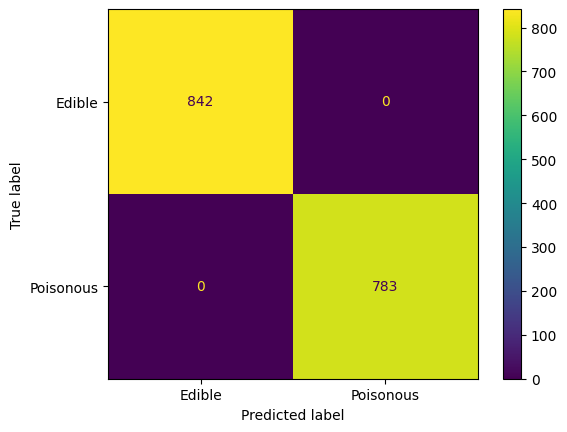

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Edible", "Poisonous"]
)

disp.plot()
plt.show()

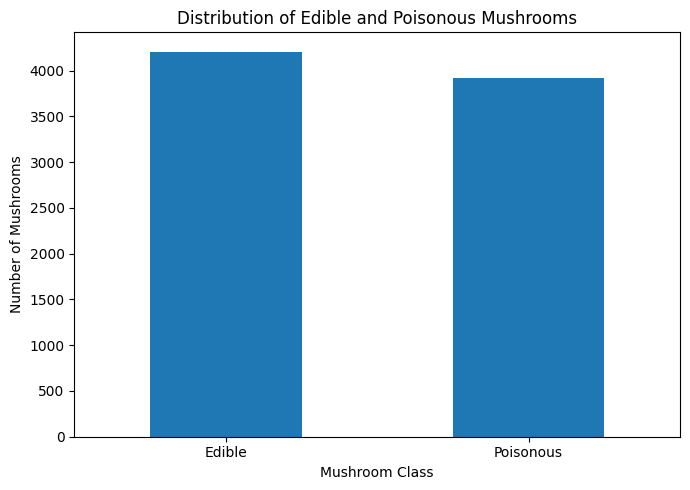

In [ ]:
import matplotlib.pyplot as plt

class_counts = df["class"].map({
    "e": "Edible",
    "p": "Poisonous"
}).value_counts()

plt.figure(figsize=(7, 5))
class_counts.plot(kind="bar")

plt.title("Distribution of Edible and Poisonous Mushrooms")
plt.xlabel("Mushroom Class")
plt.ylabel("Number of Mushrooms")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

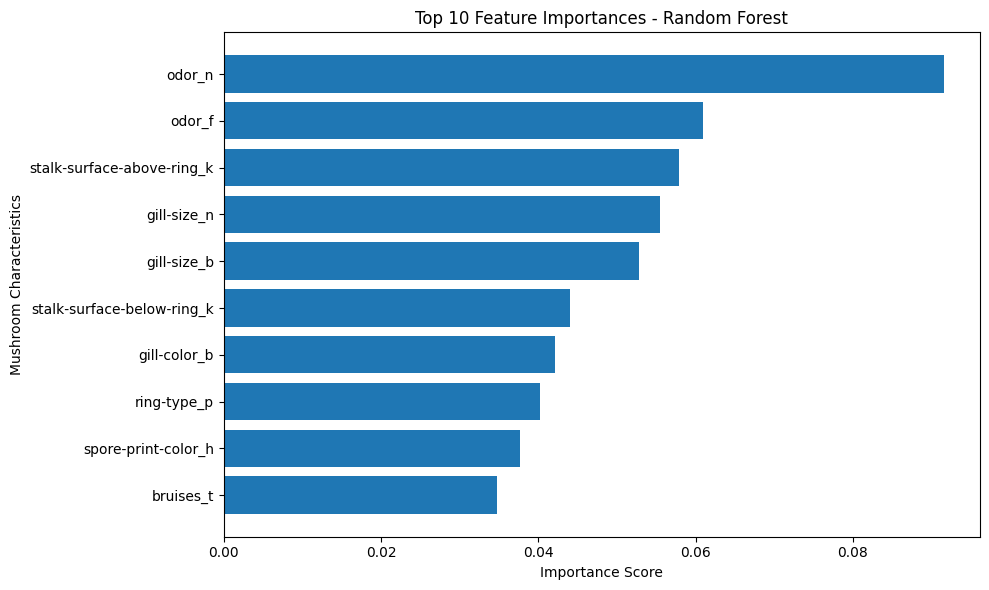

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained Random Forest
importance = best_model.feature_importances_

# Get the encoded feature names
feature_names = encoder.get_feature_names_out()

# Create a table of feature names and importance values
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Select the 10 most important encoded features
top_features = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(10)

# Plot the graph
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Mushroom Characteristics")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:

import ipywidgets as widgets
import pandas as pd
from IPython.display import display, HTML

# Mushroom characteristic meanings
meanings = {
    "cap-shape": {"b":"Bell", "c":"Conical", "x":"Convex", "f":"Flat", "k":"Knobbed", "s":"Sunken"},
    "cap-surface": {"f":"Fibrous", "g":"Grooves", "y":"Scaly", "s":"Smooth"},
    "cap-color": {"n":"Brown", "b":"Buff", "c":"Cinnamon", "g":"Gray", "r":"Green", "p":"Pink", "u":"Purple", "e":"Red", "w":"White", "y":"Yellow"},
    "bruises": {"t":"Bruises", "f":"No bruises"},
    "odor": {"a":"Almond", "l":"Anise", "c":"Creosote", "y":"Fishy", "f":"Foul", "m":"Musty", "n":"None", "p":"Pungent", "s":"Spicy"},
    "gill-attachment": {"a":"Attached", "d":"Descending", "f":"Free", "n":"Notched"},
    "gill-spacing": {"c":"Close", "w":"Crowded", "d":"Distant"},
    "gill-size": {"b":"Broad", "n":"Narrow"},
    "gill-color": {"k":"Black", "n":"Brown", "b":"Buff", "h":"Chocolate", "g":"Gray", "r":"Green", "o":"Orange", "p":"Pink", "u":"Purple", "e":"Red", "w":"White", "y":"Yellow"},
    "stalk-shape": {"e":"Enlarging", "t":"Tapering"},
    "stalk-root": {"b":"Bulbous", "c":"Club", "u":"Cup", "e":"Equal", "z":"Rhizomorphs", "r":"Rooted", "?":"Unknown"},
    "stalk-surface-above-ring": {"f":"Fibrous", "y":"Scaly", "k":"Silky", "s":"Smooth"},
    "stalk-surface-below-ring": {"f":"Fibrous", "y":"Scaly", "k":"Silky", "s":"Smooth"},
    "stalk-color-above-ring": {"n":"Brown", "b":"Buff", "c":"Cinnamon", "g":"Gray", "o":"Orange", "p":"Pink", "e":"Red", "w":"White", "y":"Yellow"},
    "stalk-color-below-ring": {"n":"Brown", "b":"Buff", "c":"Cinnamon", "g":"Gray", "o":"Orange", "p":"Pink", "e":"Red", "w":"White", "y":"Yellow"},
    "veil-type": {"p":"Partial", "u":"Universal"},
    "veil-color": {"n":"Brown", "o":"Orange", "w":"White", "y":"Yellow"},
    "ring-number": {"n":"None", "o":"One", "t":"Two"},
    "ring-type": {"c":"Cobwebby", "e":"Evanescent", "f":"Flaring", "l":"Large", "n":"None", "p":"Pendant", "s":"Sheathing", "z":"Zone"},
    "spore-print-color": {"k":"Black", "n":"Brown", "b":"Buff", "h":"Chocolate", "r":"Green", "o":"Orange", "u":"Purple", "w":"White", "y":"Yellow"},
    "population": {"a":"Abundant", "c":"Clustered", "n":"Numerous", "s":"Scattered", "v":"Several", "y":"Solitary"},
    "habitat": {"g":"Grasses", "l":"Leaves", "m":"Meadows", "p":"Paths", "u":"Urban", "w":"Waste", "d":"Woods"}
}

# Get the valid values from the original feature data
dropdowns = {}

for col in X.columns:
    codes = sorted(X[col].dropna().astype(str).unique())

    options = [
        (f"{code} - {meanings.get(col, {}).get(code, code)}", code)
        for code in codes
    ]

    dropdowns[col] = widgets.Dropdown(
        options=options,
        description=col.replace("-", " ").title() + ":",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="500px")
    )

# Heading
display(HTML("""
<div style="background:#e8f5e9; padding:20px; border-radius:12px;
            text-align:center; margin-bottom:15px;">
    <div style="font-size:48px;">🍄</div>
    <h1 style="color:#245c36; margin:5px;">Mushroom Classification</h1>
    <p>Select the mushroom's characteristics and let the trained model predict its class.</p>
</div>
"""))

# Arrange characteristics in two columns
feature_list = list(dropdowns.values())
mid = (len(feature_list) + 1) // 2

left_column = widgets.VBox(feature_list[:mid])
right_column = widgets.VBox(feature_list[mid:])

feature_layout = widgets.HBox(
    [left_column, right_column],
    layout=widgets.Layout(gap="25px", align_items="flex-start")
)

predict_button = widgets.Button(
    description="Predict Mushroom Class",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="250px", height="45px")
)

output = widgets.Output()

def predict_mushroom(button):
    with output:
        output.clear_output()

        # Create input using the same feature order used during training
        new_data = pd.DataFrame([{
            col: dropdowns[col].value for col in X.columns
        }])

        encoded_data = encoder.transform(new_data)
        prediction = best_model.predict(encoded_data)[0]

        if prediction == "e":
            display(HTML("""
            <div style="background:#e8f5e9; padding:18px; border-radius:10px;
                        text-align:center;">
                <h2 style="color:#24713a;">🍄 Prediction: EDIBLE</h2>
                <p>The model classifies this combination as edible.</p>
            </div>
            """))
        else:
            display(HTML("""
            <div style="background:#ffebee; padding:18px; border-radius:10px;
                        text-align:center;">
                <h2 style="color:#b71c1c;">⚠️ Prediction: POISONOUS</h2>
                <p>The model classifies this combination as poisonous.</p>
            </div>
            """))

        print("Model prediction:", prediction)
        print("e = edible, p = poisonous")

predict_button.on_click(predict_mushroom)

display(feature_layout)
display(predict_button)
display(output)

display(HTML("""
<p style="color:#a33; font-weight:bold;">
Safety note: This is an educational machine-learning demonstration.
Never eat a mushroom based on this model's prediction.
</p>
"""))


Button(button_style='success', description='Predict Mushroom Class', icon='check', layout=Layout(height='45px'…

Output()